# Lab 4: How Uncertain Is the Forecast, and How Does Skill Change With the Horizon? (JPM)

**Owner:** Member 4 · **Marking items covered:** 5. Uncertainty, plus the 63-day forecast files (Baseline 3, Intermediate 3, 4 and 5)

**The question this notebook answers:** How wide should the forecast range be, is it honest (coverage), and how does skill change from 1 to 63 days?


## Step 1: Set up

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tslab import config
from tslab.data import load_market_data
from tslab.team import build_features_jpm, make_dataset_jpm, FEATURE_GROUPS_JPM, ALL_FEATURES_JPM   # OUR features
from tslab.validation import walk_forward_splits, walk_forward_predict, describe_splits
from tslab.metrics import (compare_models, diebold_mariano, dm_verdict, directional_accuracy,
                           directional_accuracy_test, out_of_sample_r2, rmse, mae,
                           simple_backtest, backtest_summary)
from tslab.plots import plot_walk_forward_layout, plot_price_forecasts
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.api import SimpleExpSmoothing
from statsmodels.tsa.arima.model import ARIMA

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)
np.random.seed(config.SEED)
print("Target stock:", config.TARGET_TICKER)

Target stock: JPM


## Step 2: The data and the walk-forward folds

Every notebook in our project uses these lines, so that every model is scored on the same days.

In [2]:
frame = load_market_data()                                              # one row per JPM trading day
dataset_all = make_dataset_jpm(frame, horizon=1)                        # includes the last row (no target yet)
latest_row = dataset_all.iloc[[-1]]                                     # kept aside for a real forecast
dataset = dataset_all.dropna(subset=["target_return"])
splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))

print("Rows in the modelling table:", len(dataset))                     # expect 2789
print("Walk-forward folds         :", len(splits))                      # expect 29
print("First test day:", dataset.index[splits[0][1][0]].date(), "| last test day:", dataset.index[splits[-1][1][-1]].date())

Loaded 2989 trading days of JPM, 2015-01-02 to 2026-11-19, with 8 predictor series.
Rows in the modelling table: 2789
Walk-forward folds         : 29
First test day: 2019-10-08 | last test day: 2026-11-18


## Step 3: Settings from Member 3

Load `outputs/ml_best_params.json` if Member 3 has pushed it; otherwise use Notebook 7's settings and say so.

In [3]:
params_file = config.OUTPUT_DIR / "ml_best_params.json"
params = json.load(open(params_file)) if params_file.exists() else {"best_depth": 2, "best_rate": 0.03}
print("Gradient boosting settings:", params)

last_close, last_date = float(frame["Close"].iloc[-1]), frame.index[-1]
print(f"Last close {last_close:.2f} on {last_date.date()}")

Gradient boosting settings: {'best_alpha': 100000.0, 'best_depth': 2, 'best_rate': 0.01}
Last close 320.22 on 2026-11-19


## Step 4: 10% to 90% range and coverage

Walk-forward quantile gradient boosting for 0.10 and 0.90 (Notebook 4, Step 10). Report the coverage (target 80%), the coverage by year, and the average width in dollars. Is the model overconfident? Save `outputs/predictions_quantile.csv`.

In [4]:
# Gradient boosting settings: Member 3's (depth 2, rate 0.01), tuned on the first 1,000 days only
def make_boosting(loss="squared_error", quantile=None):
    return HistGradientBoostingRegressor(
        loss=loss, quantile=quantile,
        max_depth=params.get("best_depth", 2), learning_rate=params.get("best_rate", 0.03),
        max_iter=150, min_samples_leaf=40, l2_regularization=1.0, random_state=config.SEED)

X, y = dataset[ALL_FEATURES_JPM], dataset["target_return"]

started = time.time()
q10 = walk_forward_predict(lambda: make_boosting("quantile", 0.10), X, y, splits)   # scaler fitted on each training block only
q90 = walk_forward_predict(lambda: make_boosting("quantile", 0.90), X, y, splits)
print(f"Quantile models finished in {time.time() - started:.0f} seconds")

test = q10.notna()                                   # test days only, never training days
low  = np.minimum(q10[test], q90[test])              # the two models can occasionally cross
high = np.maximum(q10[test], q90[test])
actual = y[test]
inside = (actual >= low) & (actual <= high)

close_today = dataset.loc[test, "close"]
lower_price = close_today * np.exp(low)              # bounds are PRICES, not returns
upper_price = close_today * np.exp(high)
width = upper_price - lower_price

print(f"Coverage on {test.sum()} test days: {inside.mean():.1%}  (target 80%)")
print(f"Average width of the range: ${width.mean():.2f}  ({(width / close_today).mean():.1%} of the price)")

by_year = pd.DataFrame({"coverage": inside.groupby(inside.index.year).mean(),
                        "test_days": inside.groupby(inside.index.year).size(),
                        "avg_width_$": width.groupby(width.index.year).mean()})
display(by_year.round(3))

# Save: the date is the day being forecast (the next trading day after the forecast was made)
target_dates = frame.index[frame.index.get_indexer(dataset.index[test]) + 1]
pd.DataFrame({
    "date": target_dates,
    "forecast_made_on": dataset.index[test],
    "close_today": close_today.values,
    "actual_close": dataset.loc[test, "target_close"].values,
    "lower": lower_price.values,
    "upper": upper_price.values,
    "inside_range": inside.values,
}).to_csv(config.OUTPUT_DIR / "predictions_quantile.csv", index=False, date_format="%Y-%m-%d")
print("Saved outputs/predictions_quantile.csv")

Quantile models finished in 12 seconds
Coverage on 1789 test days: 79.8%  (target 80%)
Average width of the range: $6.12  (3.7% of the price)


,coverage,test_days,avg_width_$
Date,,,
2019,0.847,59,2.741
2020,0.688,253,4.394
2021,0.821,252,4.813
2022,0.809,251,5.204
2023,0.876,250,4.314
2024,0.821,252,5.825
2025,0.796,250,9.072
2026,0.761,222,10.541


Saved outputs/predictions_quantile.csv


**What the range shows.** Over 1,789 test days the actual next-day return fell inside the 10% to 90% range on 79.8% of days, almost exactly the 80% target. So at a one-day horizon the range is honest on average, and the model is not overconfident overall.

The average hides the bad years. In 2020 coverage fell to 68.8%: the range was learned in calm years and did not widen fast enough when the COVID crash made prices jump, so the model was overconfident exactly when it mattered most. In 2023 it was too wide (87.6%). The average width was $6.12, about 3.7% of the price; it grew from about $3 to $10 mainly because JPM's price rose.

## Step 5: Overlapping labels

Copy the gap demo from Notebook 7, Step 3 and explain why horizon h needs `gap = h - 1`.

In [5]:
h = 21
no_gap   = list(walk_forward_splits(200, initial_train=100, test_size=20, gap=0))[0]
with_gap = list(walk_forward_splits(200, initial_train=100, test_size=20, gap=h - 1))[0]

for name, (train, test_idx) in {"No gap": no_gap, f"Gap of {h - 1}": with_gap}.items():
    reaches = train[-1] + h
    print(f"{name:10s}: last training row = {train[-1]}, its label reaches row {reaches}, "
          f"first test row = {test_idx[0]}  ->  {'LEAK' if reaches > test_idx[0] else 'safe'}")

No gap    : last training row = 99, its label reaches row 120, first test row = 100  ->  LEAK
Gap of 20 : last training row = 99, its label reaches row 120, first test row = 120  ->  safe


**Why a gap is needed.** For a 21-day target, the answer in the last training row is the return over the next 21 days, so it reaches 20 days into the test block. The model would be trained on part of the test period's future. Leaving a gap of h − 1 rows between training and test removes that overlap, so every horizon in Step 6 uses `gap = h - 1`.

## Step 6: Skill at 1, 5, 21 and 63 days

Copy Notebook 7, Step 4 with `make_dataset_jpm` / `ALL_FEATURES_JPM`. Add a DM test at each horizon (`diebold_mariano(..., horizon=h)`) and Ridge as a second method. Save `outputs/horizon_skill.csv`. Explain why skill changes.

In [6]:
HORIZONS = [1, 5, 21, 63]
rows = []
started = time.time()

for h in HORIZONS:
    data_h = make_dataset_jpm(frame, horizon=h).dropna(subset=["target_return"])
    X_h, y_h = data_h[ALL_FEATURES_JPM], data_h["target_return"]
    splits_h = list(walk_forward_splits(len(data_h), config.INITIAL_TRAIN, config.TEST_SIZE, gap=h - 1))  # gap stops overlapping labels leaking

    preds = {
        "Gradient boosting": walk_forward_predict(lambda: make_boosting(), X_h, y_h, splits_h),
        "Ridge": walk_forward_predict(lambda: Ridge(alpha=params["best_alpha"]), X_h, y_h, splits_h),
    }
    q_lo = walk_forward_predict(lambda: make_boosting("quantile", 0.10), X_h, y_h, splits_h)
    q_hi = walk_forward_predict(lambda: make_boosting("quantile", 0.90), X_h, y_h, splits_h)

    m = preds["Gradient boosting"].notna()
    actual_ret   = y_h[m]
    price_today  = data_h.loc[m, "close"]
    actual_price = data_h.loc[m, "target_close"]
    lo, hi = np.minimum(q_lo[m], q_hi[m]), np.maximum(q_lo[m], q_hi[m])
    coverage = float(((actual_ret >= lo) & (actual_ret <= hi)).mean())
    width_pct = float((np.exp(hi) - np.exp(lo)).mean() * 100)
    common = {"horizon": h, "test_rows": int(m.sum()), "independent_periods": int(m.sum() // h),
              "share_actually_up": float((actual_ret > 0).mean())}

    rows.append({**common, "method": "Naive (no change)",
                 "rmse_price": rmse(actual_price, price_today), "mae_price": mae(actual_price, price_today),
                 "r2_oos": 0.0, "directional_accuracy": np.nan, "dm_stat": np.nan, "dm_p": np.nan,
                 "verdict": "baseline", "coverage_10_90": np.nan, "range_width_pct": np.nan})

    for name, p in preds.items():
        pred = p[m]
        stat, p_dm = diebold_mariano(actual_ret, pred, np.zeros(len(pred)), horizon=h)
        rows.append({**common, "method": name,
                     "rmse_price": rmse(actual_price, price_today * np.exp(pred)),
                     "mae_price": mae(actual_price, price_today * np.exp(pred)),
                     "r2_oos": out_of_sample_r2(actual_ret, pred),
                     "directional_accuracy": directional_accuracy(actual_ret, pred),
                     "dm_stat": stat, "dm_p": p_dm, "verdict": dm_verdict(stat, p_dm),
                     "coverage_10_90": coverage if name == "Gradient boosting" else np.nan,
                     "range_width_pct": width_pct if name == "Gradient boosting" else np.nan})
    print(f"  horizon {h:>2} days done ({time.time() - started:.0f} s)")

horizon_skill = pd.DataFrame(rows)
horizon_skill.to_csv(config.OUTPUT_DIR / "horizon_skill.csv", index=False)
print("Saved outputs/horizon_skill.csv")
display(horizon_skill.set_index(["horizon", "method"]).round(4))

  horizon  1 days done (15 s)
  horizon  5 days done (28 s)
  horizon 21 days done (42 s)
  horizon 63 days done (56 s)
Saved outputs/horizon_skill.csv


test_rows  independent_periods  share_actually_up  \
horizon method                                                                 
1       Naive (no change)       1789                 1789             0.5344   
        Gradient boosting       1789                 1789             0.5344   
        Ridge                   1789                 1789             0.5344   
5       Naive (no change)       1781                  356             0.5772   
        Gradient boosting       1781                  356             0.5772   
        Ridge                   1781                  356             0.5772   
21      Naive (no change)       1749                   83             0.6112   
        Gradient boosting       1749                   83             0.6112   
        Ridge                   1749                   83             0.6112   
63      Naive (no change)       1665                   26             0.7063   
        Gradient boosting       1665                   26             0.7063   
        Ridge                   1665                   26             0.7063   

                           rmse_price  mae_price  r2_oos  \
horizon method                                             
1       Naive (no change)      2.9737     2.0128  0.0000   
        Gradient boosting      2.9930     2.0200 -0.0136   
        Ridge                  2.9725     2.0066  0.0005   
5       Naive (no change)      6.2551     4.5686  0.0000   
        Gradient boosting      6.3287     4.6122 -0.0507   
        Ridge                  6.2344     4.5111  0.0019   
21      Naive (no change)     12.6771     9.5629  0.0000   
        Gradient boosting     12.5876     9.6359 -0.0746   
        Ridge                 12.4379     9.3721  0.0128   
63      Naive (no change)     21.6228    17.0937  0.0000   
        Gradient boosting     21.4069    17.1389 -0.1432   
        Ridge                 19.8621    15.8080  0.0742   

                           directional_accuracy  dm_stat    dm_p  \
horizon method                                                     
1       Naive (no change)                   NaN      NaN     NaN   
        Gradient boosting                0.5238   1.5647  0.1178   
        Ridge                            0.5355  -0.2353  0.8140   
5       Naive (no change)                   NaN      NaN     NaN   
        Gradient boosting                0.5323   2.3528  0.0187   
        Ridge                            0.5772  -0.2314  0.8170   
21      Naive (no change)                   NaN      NaN     NaN   
        Gradient boosting                0.5380   1.4022  0.1610   
        Ridge                            0.6112  -0.4081  0.6833   
63      Naive (no change)                   NaN      NaN     NaN   
        Gradient boosting                0.5712   0.9287  0.3532   
        Ridge                            0.7063  -0.8032  0.4220   

                                                  verdict  coverage_10_90  \
horizon method                                                              
1       Naive (no change)                        baseline             NaN   
        Gradient boosting       No significant difference          0.7982   
        Ridge                   No significant difference             NaN   
5       Naive (no change)                        baseline             NaN   
        Gradient boosting  Significantly WORSE than naive          0.7788   
        Ridge                   No significant difference             NaN   
21      Naive (no change)                        baseline             NaN   
        Gradient boosting       No significant difference          0.7267   
        Ridge                   No significant difference             NaN   
63      Naive (no change)                        baseline             NaN   
        Gradient boosting       No significant difference          0.6661   
        Ridge                   No significant difference             NaN   

                           range_

**What the horizons show.**

- No model beats the naive forecast at any horizon: every DM p-value is above 0.05, except gradient boosting at 5 days, which is significantly *worse* than naive (p = 0.019).
- Ridge looks best at 63 days ($19.86 against $21.62 for naive), but its directional accuracy is exactly the share of periods in which JPM rose (70.6%). Ridge simply predicts "up" every time, so its lower error comes from JPM's upward drift in a rising market, not from skill, and the DM test finds no significant difference (p = 0.42).
- Skill changes with the horizon for three reasons. Errors build up over a longer period. There are far fewer independent test periods (1,789 at one day, but only 26 separate quarters at 63 days), so long-horizon results rest on very little evidence. And the range must widen.
- The range becomes more overconfident as the horizon grows: coverage falls from 79.8% at 1 day to 77.9%, 72.7% and only 66.6% at 63 days, against a target of 80%. Its width grows about 6.4 times from 1 to 63 days, less than the √63 ≈ 7.9 that a random walk would suggest, so it does not widen enough.

## Step 7: The 63-day path on real trading days

Copy Notebook 7, Step 5, using these NYSE trading days (20 Nov 2026 to 23 Feb 2027).

In [7]:
nyse_holidays = ["2026-11-26", "2026-12-25", "2027-01-01", "2027-01-18", "2027-02-15"]
trading_day = pd.offsets.CustomBusinessDay(holidays=nyse_holidays)
future_dates = pd.date_range(last_date + trading_day, periods=63, freq=trading_day)
print(future_dates[0].date(), "to", future_dates[-1].date())

today_X = latest_row[ALL_FEATURES_JPM]                 # predictors known at the close of 19 Nov 2026
print("Forecasting from:", latest_row.index[0].date())

path_rows = []
started = time.time()
for h in range(1, 64):
    data_h = make_dataset_jpm(frame, horizon=h).dropna(subset=["target_return"])
    X_h, y_h = data_h[ALL_FEATURES_JPM], data_h["target_return"]
    scaler = StandardScaler().fit(X_h)                 # final model: all known history, no test period left
    Xs, today = scaler.transform(X_h), scaler.transform(today_X)

    point = make_boosting().fit(Xs, y_h).predict(today)[0]
    low   = make_boosting("quantile", 0.10).fit(Xs, y_h).predict(today)[0]
    high  = make_boosting("quantile", 0.90).fit(Xs, y_h).predict(today)[0]
    low, point, high = sorted([low, point, high])     # separately fitted quantiles can cross
    ridge = Ridge(alpha=params["best_alpha"]).fit(Xs, y_h).predict(today)[0]

    path_rows.append({"horizon": h, "date": future_dates[h - 1],
                      "gradient_boosting": last_close * np.exp(point),
                      "lower": last_close * np.exp(low), "upper": last_close * np.exp(high),
                      "ridge": last_close * np.exp(ridge)})
print(f"Done in {time.time() - started:.0f} seconds")

paths = pd.DataFrame(path_rows)
paths.round(2).iloc[[0, 4, 20, 41, 62]]

2026-11-20 to 2027-02-23
Forecasting from: 2026-11-19
Done in 33 seconds


,horizon,date,gradient_boosting,lower,upper,ridge
0,1,2026-11-20,320.45,312.75,327.53,320.58
4,5,2026-11-27,321.50,308.07,338.64,321.56
20,21,2026-12-21,330.14,300.12,362.91,325.93
41,42,2027-01-22,337.45,301.29,380.60,330.42
62,63,2027-02-23,344.19,296.17,390.33,335.96


## Step 8: Save forecast_basic.csv (exact column names)

The brief requires exactly `date, forecast, lower, upper`.

In [8]:
basic = pd.DataFrame({"date": paths["date"], "forecast": paths["gradient_boosting"],
                      "lower": paths["lower"], "upper": paths["upper"]})
basic.to_csv(config.DATA_DIR / "forecast_basic.csv", index=False, date_format="%Y-%m-%d")
assert list(pd.read_csv(config.DATA_DIR / "forecast_basic.csv").columns) == ["date", "forecast", "lower", "upper"]
print("Saved data/forecast_basic.csv:", len(basic), "rows")
basic.round(2).iloc[[0, 20, 62]]

Saved data/forecast_basic.csv: 63 rows


,date,forecast,lower,upper
0,2026-11-20,320.45,312.75,327.53
20,2026-12-21,330.14,300.12,362.91
62,2027-02-23,344.19,296.17,390.33


## Step 9: Save forecast_intermediate.csv

63 rows: `date, naive, ses, arima, ridge, gradient_boosting, lower, upper`.

In [9]:
# Member 2's chosen order: ARIMA(0,1,0) by AIC, which is the same as the naive forecast (a random walk)
arima_fit = ARIMA(np.log(frame["Close"]).to_numpy(), order=(0, 1, 0)).fit()
arima_path = np.exp(arima_fit.forecast(63))

ses_fit = SimpleExpSmoothing(frame["Close"].to_numpy(), initialization_method="estimated").fit()
ses_path = ses_fit.forecast(63)                       # a flat line at the smoothed level

intermediate = pd.DataFrame({
    "date": paths["date"],
    "naive": last_close,                               # "no change": the last close on every row
    "ses": ses_path,
    "arima": arima_path,
    "ridge": paths["ridge"],
    "gradient_boosting": paths["gradient_boosting"],
    "lower": paths["lower"],
    "upper": paths["upper"],
})
intermediate.to_csv(config.DATA_DIR / "forecast_intermediate.csv", index=False, date_format="%Y-%m-%d")
print("Saved data/forecast_intermediate.csv:", intermediate.shape)
intermediate.round(2).iloc[[0, 20, 62]]

Saved data/forecast_intermediate.csv: (63, 8)


,date,naive,ses,arima,ridge,gradient_boosting,lower,upper
0,2026-11-20,320.22,320.41,320.22,320.58,320.45,312.75,327.53
20,2026-12-21,320.22,320.41,320.22,325.93,330.14,300.12,362.91
62,2027-02-23,320.22,320.41,320.22,335.96,344.19,296.17,390.33


ARIMA uses Member 2's order, ARIMA(0,1,0), chosen by AIC on the first training block. That model is a random walk, so its forecast is identical to the naive forecast ($320.22 on every day). Simple exponential smoothing is also a flat line ($320.41).

## Step 10: metrics_by_method.csv for Power BI

Score every column of `outputs/predictions_classical.csv` and `outputs/predictions_ml.csv` on the common days: `method, family, rmse_price, mae_price, r2_oos, directional_accuracy, dm_stat, dm_p, beats_naive`.

In [10]:
classical = pd.read_csv(config.OUTPUT_DIR / "predictions_classical.csv", index_col=0, parse_dates=True)
ml = pd.read_csv(config.OUTPUT_DIR / "predictions_ml.csv", index_col=0, parse_dates=True)
all_preds = pd.concat([classical, ml], axis=1).reindex(dataset.index)
common = all_preds.dropna().index                     # the days on which every method made a forecast
print("Common test days:", len(common), "|", common[0].date(), "to", common[-1].date())

scored = dataset.loc[common]
actual_ret, actual_price, price_today = scored["target_return"], scored["target_close"], scored["close"]

families = {"Naive (no change)": "baseline", "Drift": "classical", "Simple exponential smoothing": "classical",
            "ARIMA": "classical", "ARMA(1,0)": "classical", "ARMAX": "classical",
            "Ridge": "machine learning", "Gradient boosting": "machine learning"}

rows = []
for name in all_preds.columns:
    pred = all_preds.loc[common, name]
    predicted_price = price_today * np.exp(pred)       # return -> price
    mostly_zero = (np.abs(pred) < 1e-8).mean() > 0.5   # naive and ARIMA(0,1,0) predict "no change"
    if name == "Naive (no change)":
        stat, p_dm, beats = np.nan, np.nan, "baseline"
    else:
        stat, p_dm = diebold_mariano(actual_ret, pred, np.zeros(len(pred)))
        beats = "Yes" if (stat < 0 and p_dm < 0.05) else "No"
    rows.append({"method": name, "family": families.get(name, "other"),
                 "rmse_price": rmse(actual_price, predicted_price),
                 "mae_price": mae(actual_price, predicted_price),
                 "r2_oos": out_of_sample_r2(actual_ret, pred),
                 "directional_accuracy": np.nan if mostly_zero else directional_accuracy(actual_ret, pred),
                 "dm_stat": stat, "dm_p": p_dm, "beats_naive": beats})

metrics = pd.DataFrame(rows)
metrics.to_csv(config.OUTPUT_DIR / "metrics_by_method.csv", index=False)
print(f"Share of test days on which JPM rose: {(actual_ret > 0).mean():.1%}")
print("Saved outputs/metrics_by_method.csv")
metrics.round(4)

Common test days: 1789 | 2019-10-08 to 2026-11-18
Share of test days on which JPM rose: 53.4%
Saved outputs/metrics_by_method.csv


,method,family,rmse_price,mae_price,r2_oos,directional_accuracy,dm_stat,dm_p,beats_naive
0,Naive (no change),baseline,2.9737,2.0128,0.0000,NaN,NaN,NaN,baseline
1,Drift,classical,2.9723,2.0060,0.0007,0.5344,-0.4113,0.6809,No
2,Simple exponential smoothing,classical,2.9797,2.0184,-0.0062,0.4902,1.0161,0.3097,No
3,ARIMA,classical,2.9737,2.0128,0.0000,NaN,1.2113,0.2259,No
4,"ARMA(1,0)",classical,2.9816,2.0193,-0.0092,0.5137,1.1090,0.2676,No
5,ARMAX,classical,3.0005,2.0294,-0.0145,0.5271,1.0358,0.3004,No
6,Ridge,machine learning,2.9725,2.0066,0.0005,0.5355,-0.2353,0.8140,No
7,Gradient boosting,machine learning,2.9958,2.0223,-0.0180,0.5266,1.7619,0.0783,No


On the same 1,789 test days, none of the eight methods beats the naive forecast: no method has both a lower error and a DM p-value below 0.05. The closest, Drift and Ridge, are only $0.001 better per day and far from significant (p = 0.68 and 0.81). JPM rose on 53.4% of test days, so a directional accuracy of about 53% is no better than always predicting "up".

## Step 11: Chart

The last year of actual closes, the 63-day forecast and the shaded range (the same picture as Power BI).

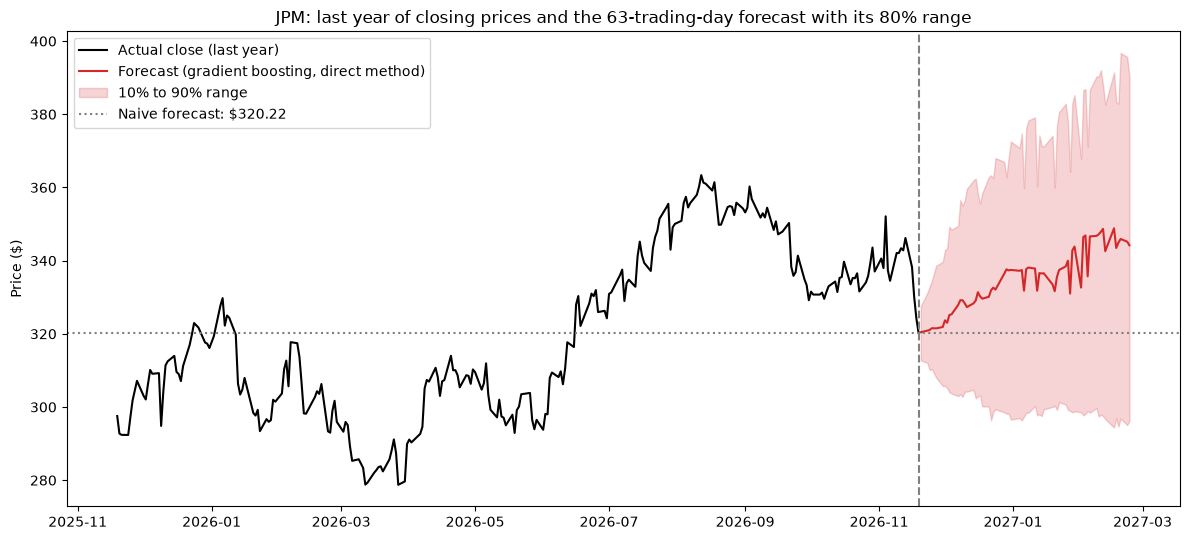

In [11]:
history = frame["Close"].iloc[-252:]                  # about one year of trading days

plt.figure(figsize=(12, 5.5))
plt.plot(history, color="black", label="Actual close (last year)")
plt.plot(basic["date"], basic["forecast"], color="tab:red", label="Forecast (gradient boosting, direct method)")
plt.fill_between(basic["date"], basic["lower"], basic["upper"], color="tab:red", alpha=0.2, label="10% to 90% range")
plt.axhline(last_close, color="grey", linestyle=":", label=f"Naive forecast: ${last_close:.2f}")
plt.axvline(last_date, color="grey", linestyle="--")
plt.title("JPM: last year of closing prices and the 63-trading-day forecast with its 80% range")
plt.ylabel("Price ($)"); plt.legend(loc="upper left"); plt.tight_layout(); plt.show()


## Conclusion

**Does the model beat the naive forecast? No.** At horizons of 1, 5, 21 and 63 days, no model was significantly better than "tomorrow will be the same as today", and gradient boosting was significantly worse at 5 days. This is a valid finding: JPM's daily price moves were not predictable from our predictors.

**The 63-day forecast.** The central line ends at $344.19 on 23 February 2027 (+7.5% from $320.22), with an 80% range of $296.17 to $390.33. Because no model beats naive, the central line should not be trusted; treat it as roughly "no change". The range is the useful part, but in our tests it held the real price only 67% of the time at 63 days instead of 80%, so the true uncertainty is wider than the range shows.

**For the portfolio manager:** plan for the range, not the line, and allow for moves larger than the range suggests, especially in a crisis like 2020.